# Jour 1 — Préparation et exploration des données (Chapitre 1)

**Projet final « Apprentissage non supervisé » — Master BDA/IA**
Segmentation de clientèle bancaire — jeu *Bank Marketing* (UCI, `bank-additional-full.csv`).

Objectifs du jour :
1. Charger les données et décrire la matrice de données (types de variables).
2. Nettoyage : valeurs `unknown`, doublons, valeurs aberrantes.
3. EDA : statistiques descriptives, histogrammes, scatter plots, heatmap de corrélation.
4. Construire deux représentations : **(a)** one-hot + standardisation $z=(x-\mu)/\sigma$ ; **(b)** données mixtes brutes (Gower / K-prototypes).
5. Réduction de dimension : PCA (variance expliquée), t-SNE et UMAP en 2D.

> La variable cible `y` est **mise de côté** dès le chargement : elle ne sert qu'aux indices externes du Jour 4.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

from src.config import SEED, SAMPLE_SIZE, DATA_PROC, FIGURES, MODELS, RESULTS
from src.preprocessing import (load_raw, preprocess, stratified_sample, NUM_FEATURES,
                               BIN_FEATURES, CAT_FEATURES, gower_cat_mask)

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.dpi"] = 110
np.random.seed(SEED)
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Chargement et description de la matrice de données

In [2]:
raw = load_raw()
print("Dimensions :", raw.shape)
raw.head()

Dimensions : (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
types = pd.DataFrame({
    "variable": raw.columns,
    "dtype": [str(raw[c].dtype) for c in raw.columns],
    "n_modalites": [raw[c].nunique() for c in raw.columns],
})
nature = {
    "age": "continue (entière)", "duration": "continue (entière)", "campaign": "discrète",
    "pdays": "discrète (999 = jamais)", "previous": "discrète",
    "emp.var.rate": "continue", "cons.price.idx": "continue", "cons.conf.idx": "continue",
    "euribor3m": "continue", "nr.employed": "continue",
    "job": "nominale", "marital": "nominale", "education": "ordinale",
    "default": "binaire (+unknown)", "housing": "binaire (+unknown)", "loan": "binaire (+unknown)",
    "contact": "binaire", "month": "nominale (calendrier)", "day_of_week": "nominale (calendrier)",
    "poutcome": "nominale", "y": "binaire (CIBLE)",
}
types["nature"] = types["variable"].map(nature)
types.to_csv(RESULTS / "j1_types_variables.csv", index=False)
types

,variable,dtype,n_modalites,nature
0,age,int64,78,continue (entière)
1,job,object,12,nominale
2,marital,object,4,nominale
3,education,object,8,ordinale
4,default,object,3,binaire (+unknown)
5,housing,object,3,binaire (+unknown)
6,loan,object,3,binaire (+unknown)
7,contact,object,2,binaire
8,month,object,10,nominale (calendrier)
9,day_of_week,object,5,nominale (calendrier)


La matrice de données comporte **41 188 individus × 21 variables** : 10 numériques (dont 5 indicateurs macro-économiques identiques pour tous les clients appelés le même mois) et 11 qualitatives. On distingue continues, discrètes, nominales, une ordinale (`education`) et des binaires — d'où la nécessité de mesures adaptées aux **données mixtes** (Gower, K-prototypes).

## 2. Nettoyage : `unknown`, doublons, valeurs aberrantes

In [4]:
unk = pd.Series({c: (raw[c] == "unknown").sum() for c in raw.columns if raw[c].dtype == object})
unk = unk[unk > 0].sort_values(ascending=False)
miss = pd.DataFrame({"n_unknown": unk, "%": (100 * unk / len(raw)).round(2)})
print("Doublons exacts :", raw.duplicated().sum())
print("Valeurs NaN     :", raw.isna().sum().sum())
miss

Doublons exacts : 12
Valeurs NaN     : 0


,n_unknown,%
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


In [5]:
num_raw = ["age", "duration", "campaign", "previous", "emp.var.rate", "cons.price.idx",
           "cons.conf.idx", "euribor3m", "nr.employed"]
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
out = pd.DataFrame({"n_outliers_IQR": {c: iqr_outliers(raw[c]) for c in num_raw}})
out["%"] = (100 * out["n_outliers_IQR"] / len(raw)).round(2)
out["max"] = raw[num_raw].max()
out

,n_outliers_IQR,%,max
age,469,1.14,98.000
duration,2963,7.19,4918.000
campaign,2406,5.84,56.000
previous,5625,13.66,7.000
emp.var.rate,0,0.00,1.400
cons.price.idx,0,0.00,94.767
cons.conf.idx,447,1.09,-26.900
euribor3m,0,0.00,5.045
nr.employed,0,0.00,5228.100


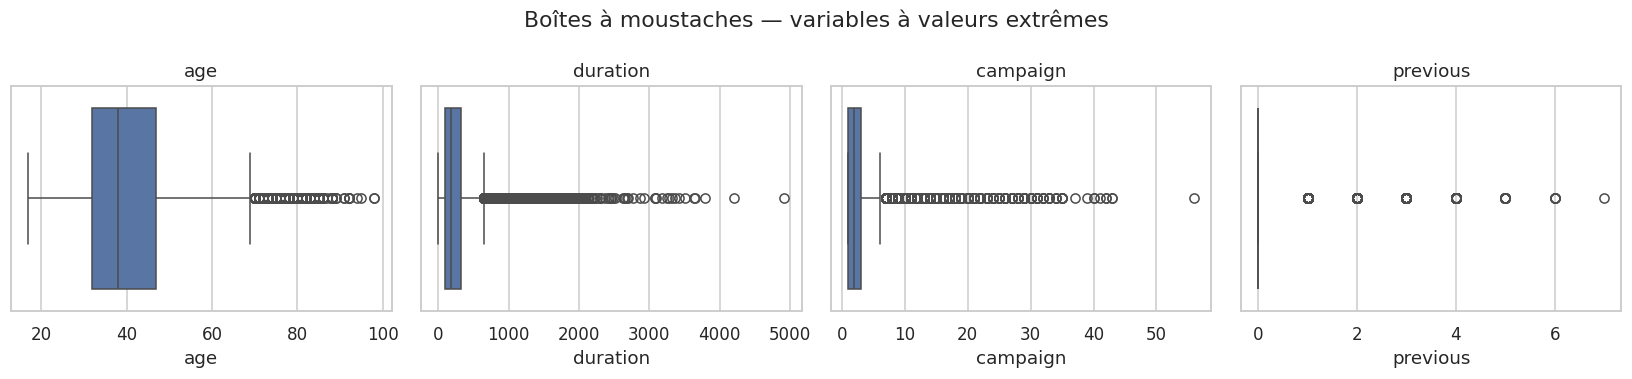

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, c in zip(axes, ["age", "duration", "campaign", "previous"]):
    sns.boxplot(x=raw[c], ax=ax, color="#4C72B0"); ax.set_title(c)
fig.suptitle("Boîtes à moustaches — variables à valeurs extrêmes"); fig.tight_layout(); save(fig, "j1_boxplots")

**Décisions de nettoyage**

| Problème | Décision | Justification |
|---|---|---|
| 12 doublons exacts | suppression | aucune information supplémentaire |
| `job` (330), `marital` (80) `unknown` | imputation par le mode | < 1 % des lignes |
| `education` (1 731) `unknown` | imputation par le mode **au sein du métier** | 4,2 % ; l'éducation dépend fortement du métier |
| `housing`/`loan` (990, mêmes lignes) | imputation par le mode | 2,4 % |
| `default` : `unknown` = 21 %, `yes` = 3 cas | variable binaire `default_flag` = « non déclaré sans défaut » | `unknown` est informatif (refus de déclarer), `yes` quasi absent |
| `campaign` (max 56, très asymétrique) | écrêtage au 99ᵉ centile (14) puis `log(1+x)` | évite qu'une poignée de clients ne domine les distances euclidiennes |
| `age` (aberrants IQR > 69 ans) | **conservés** | valeurs réelles (retraités), segment métier pertinent |
| `previous` (aberrants IQR dès 1) | **conservés** | 86 % de zéros : tout contact antérieur est « atypique » mais signifiant |

## 3. Analyse exploratoire (EDA)

In [7]:
raw[num_raw].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


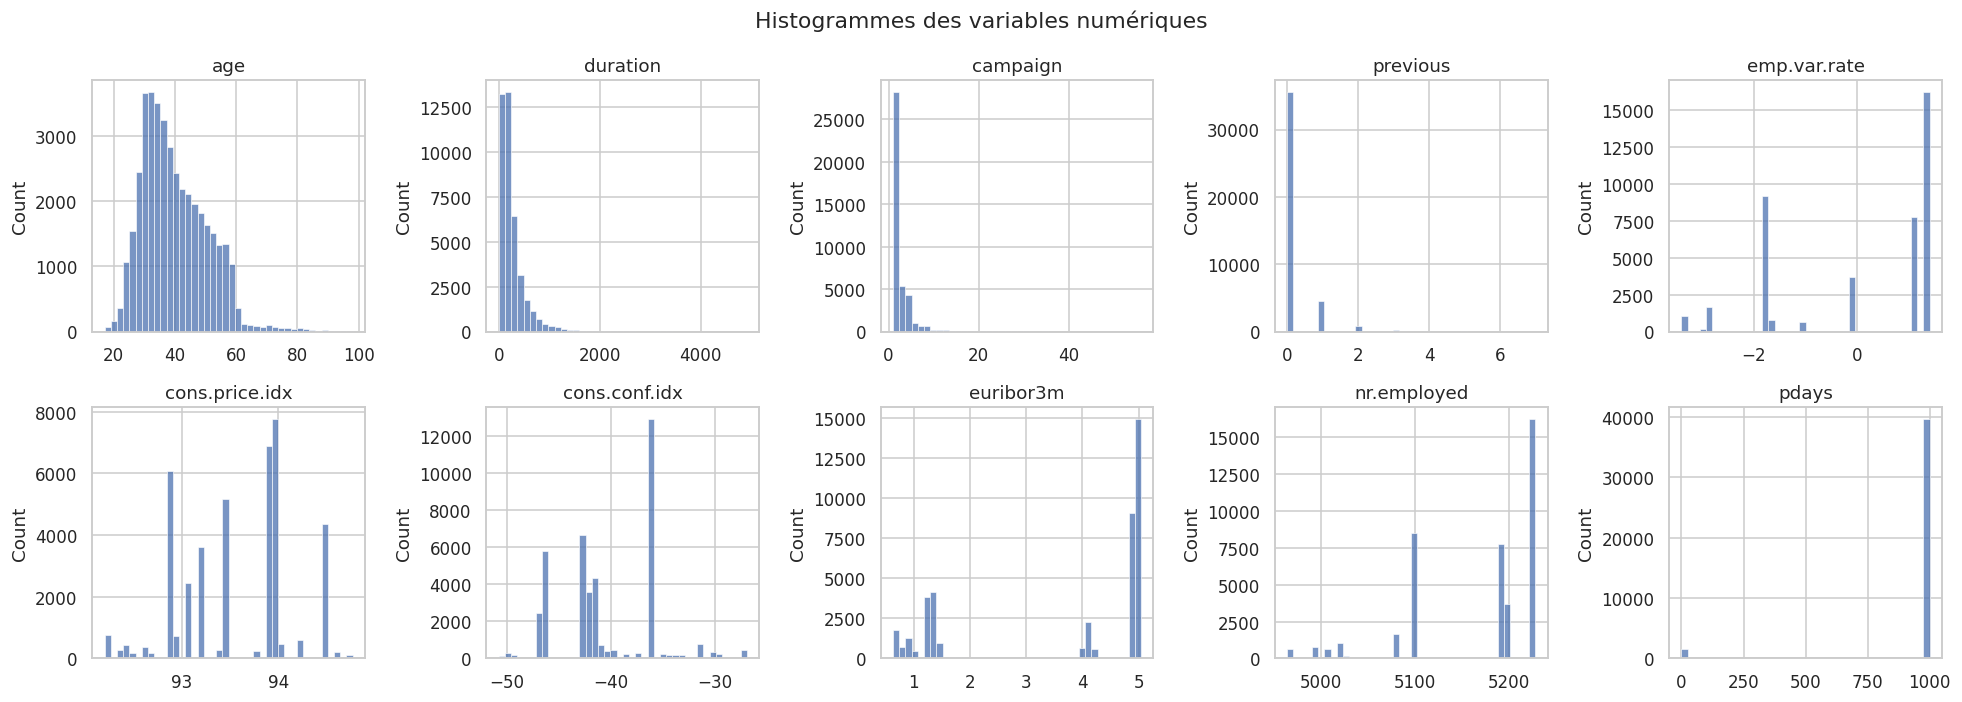

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for ax, c in zip(axes.ravel(), num_raw + ["pdays"]):
    sns.histplot(raw[c], bins=40, ax=ax, color="#4C72B0"); ax.set_title(c); ax.set_xlabel("")
fig.suptitle("Histogrammes des variables numériques"); fig.tight_layout(); save(fig, "j1_histogrammes")

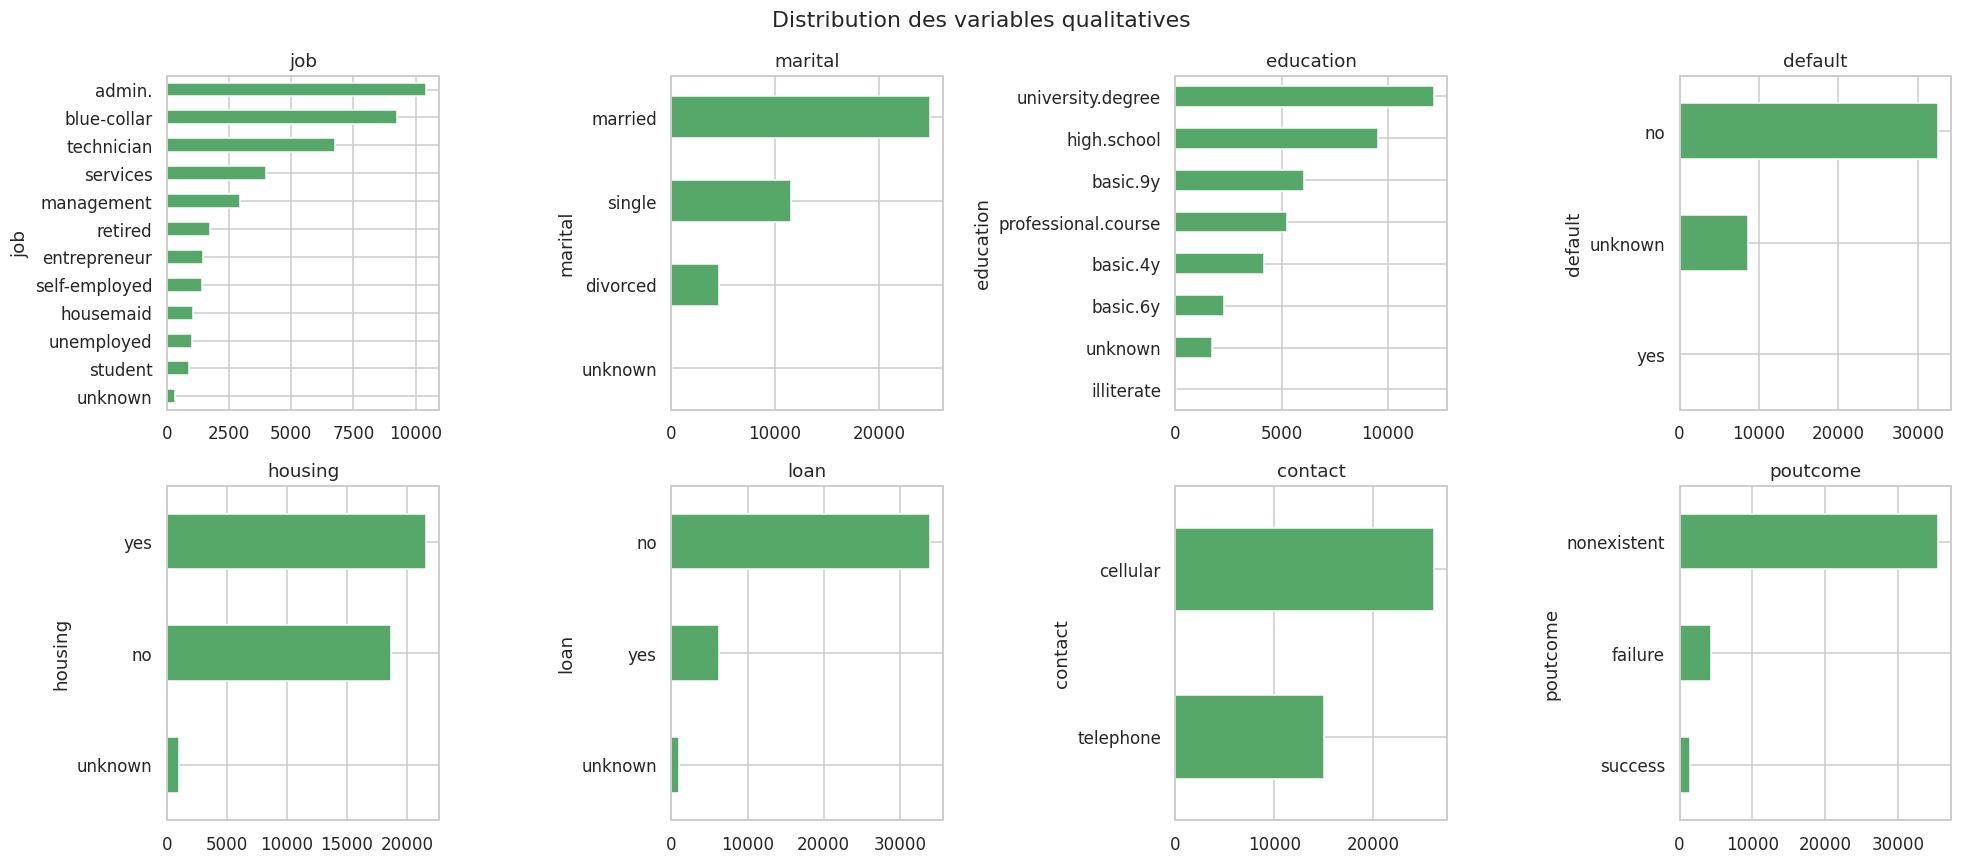

In [9]:
cats = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cats):
    raw[c].value_counts().plot.barh(ax=ax, color="#55A868"); ax.set_title(c); ax.invert_yaxis()
fig.suptitle("Distribution des variables qualitatives"); fig.tight_layout(); save(fig, "j1_barplots_cat")

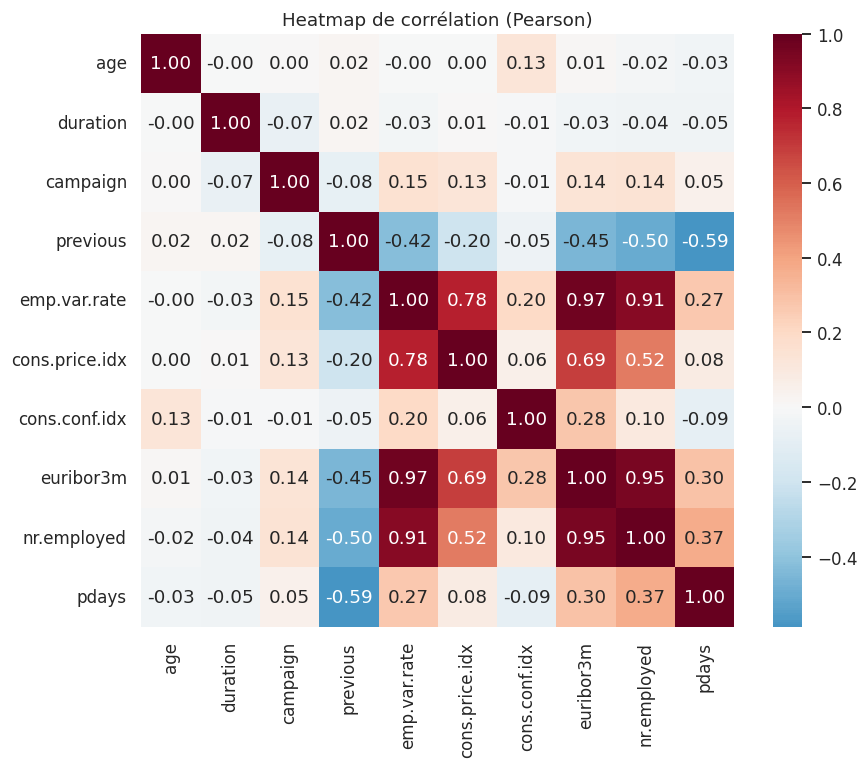

In [10]:
corr = raw[num_raw + ["pdays"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, square=True)
ax.set_title("Heatmap de corrélation (Pearson)"); save(fig, "j1_heatmap_corr")

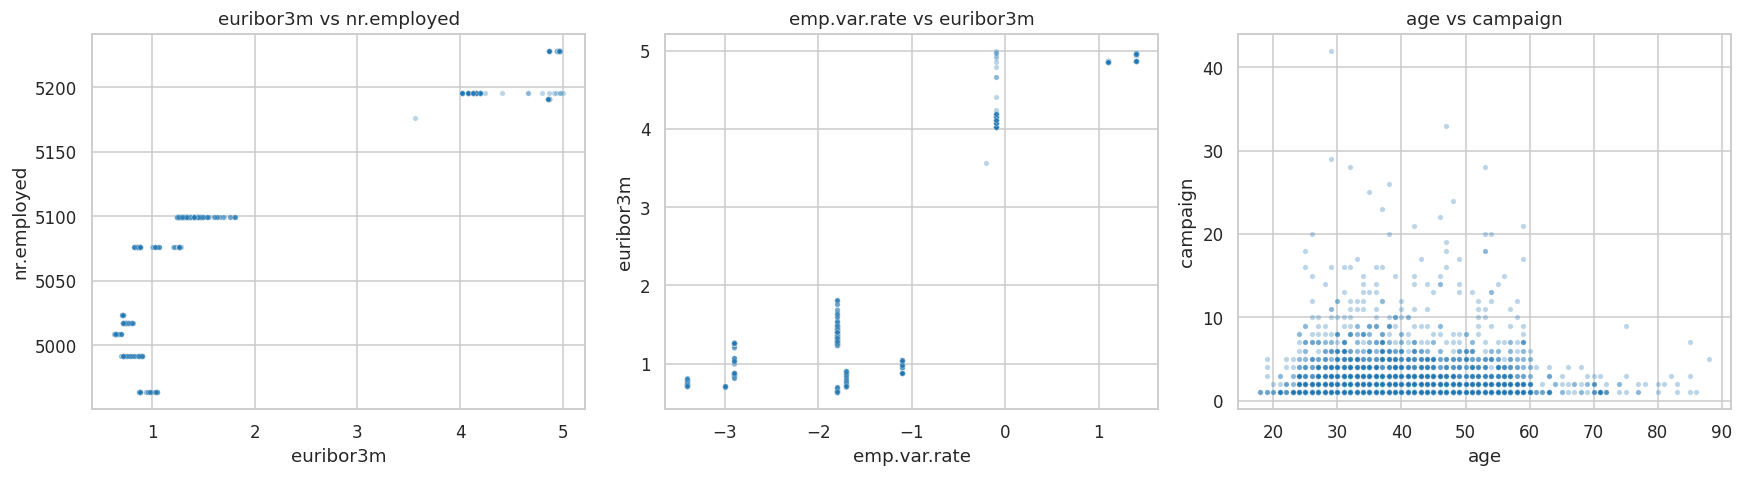

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
s = raw.sample(4000, random_state=SEED)
sns.scatterplot(data=s, x="euribor3m", y="nr.employed", alpha=.3, ax=axes[0], s=12)
sns.scatterplot(data=s, x="emp.var.rate", y="euribor3m", alpha=.3, ax=axes[1], s=12)
sns.scatterplot(data=s, x="age", y="campaign", alpha=.3, ax=axes[2], s=12)
for ax in axes: ax.set_title(f"{ax.get_xlabel()} vs {ax.get_ylabel()}")
fig.tight_layout(); save(fig, "j1_scatter")

In [12]:
print("Répartition de la cible (information seulement, non utilisée à l'entraînement) :")
print(raw["y"].value_counts(normalize=True).round(4))

Répartition de la cible (information seulement, non utilisée à l'entraînement) :
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


**Enseignements de l'EDA**

- Les indicateurs macro-économiques `emp.var.rate`, `euribor3m`, `nr.employed` sont **quasi colinéaires** (r = 0,91 à 0,97) et `cons.price.idx` leur est fortement lié (r ≈ 0,7). Les garder tous reviendrait à pondérer 4 fois la même information dans une distance euclidienne → on conserve **`euribor3m`** (représentant du cycle économique) et **`cons.conf.idx`** (confiance des ménages, peu corrélée aux autres).
- `duration` (durée du dernier appel) n'est connue **qu'après** l'appel : l'utiliser pour segmenter des clients *avant* une campagne serait une **fuite d'information**. Elle est exclue.
- `month` et `day_of_week` décrivent le **calendrier de l'appel**, pas le client : exclues de la segmentation.
- `pdays` vaut 999 (« jamais contacté ») dans 96 % des cas ; l'information est déjà portée par `previous` et `poutcome` : exclue.
- La cible est **déséquilibrée** (11,3 % de souscriptions) : l'échantillon de travail sera **stratifié** sur `y`.

## 4. Prétraitement réutilisable et deux représentations

Toute la logique est encapsulée dans `src/preprocessing.py` (fonction `preprocess()`), réutilisée par tous les notebooks et par l'application Streamlit.

Variables de segmentation retenues (13) :
- **numériques / ordinale** (6) : `age`, `campaign_log`, `previous`, `euribor3m`, `cons.conf.idx`, `education_level` (0 = illettré … 6 = université) ;
- **binaires** (4) : `housing`, `loan`, `default_flag`, `contact_cellular` ;
- **nominales** (3) : `job`, `marital`, `poutcome`.

In [13]:
data = preprocess()
clean, y, X_a, mixed = data["clean"], data["y"], data["X_a"], data["mixed"]
print(data["report"])
print("Représentation (a) — one-hot + z-score :", X_a.shape)
print("Représentation (b) — mixte brute       :", mixed.shape)
mixed.head()

{'n_raw': 41188, 'n_duplicates': 12, 'unknown_counts': {'job': 330, 'marital': 80, 'education': 1730, 'default': 8596, 'housing': 990, 'loan': 990, 'contact': 0, 'month': 0, 'day_of_week': 0, 'poutcome': 0, 'y': 0}, 'campaign_capped': 406, 'n_clean': 41176}
Représentation (a) — one-hot + z-score : (41176, 27)
Représentation (b) — mixte brute       : (41176, 13)


,age,campaign_log,previous,euribor3m,cons.conf.idx,education_level,housing,loan,default_flag,contact_cellular,job,marital,poutcome
0,56.0,0.693147,0.0,4.857,-36.4,1.0,no,no,no,no,housemaid,married,nonexistent
1,57.0,0.693147,0.0,4.857,-36.4,4.0,no,no,yes,no,services,married,nonexistent
2,37.0,0.693147,0.0,4.857,-36.4,4.0,yes,no,no,no,services,married,nonexistent
3,40.0,0.693147,0.0,4.857,-36.4,2.0,no,no,no,no,admin.,married,nonexistent
4,56.0,0.693147,0.0,4.857,-36.4,4.0,no,yes,no,no,services,married,nonexistent


In [14]:
pd.DataFrame(X_a, columns=data["feature_names"]).describe().T[["mean", "std", "min", "max"]].round(2).head(12)

,mean,std,min,max
age,0.00,1.00,-2.21,5.56
campaign_log,0.00,1.00,-0.88,3.33
previous,0.00,1.00,-0.35,13.79
euribor3m,-0.00,1.00,-1.72,0.82
cons.conf.idx,-0.00,1.00,-2.23,2.94
education_level,-0.00,1.00,-2.55,1.12
housing,0.55,0.50,0.00,1.00
loan,0.15,0.36,0.00,1.00
default_flag,0.21,0.41,0.00,1.00
contact_cellular,0.63,0.48,0.00,1.00


Les variables numériques de (a) sont centrées-réduites (moyenne 0, écart-type 1) ; les binaires et indicatrices one-hot restent en 0/1. La représentation (b) garde les variables qualitatives sous forme de modalités (texte) et les numériques dans leur unité d'origine : c'est la distance de **Gower** qui se chargera de la normalisation (par l'étendue).

### Échantillon stratifié de travail (n = 4 000)
Les méthodes à matrice de distances (hiérarchique, Gower, K-medoids) ont une complexité mémoire en $O(n^2)$ : on travaille sur un **échantillon aléatoire stratifié** de 4 000 clients, utilisé ensuite par **toutes** les méthodes pour une comparaison équitable.

In [15]:
sample_idx = stratified_sample(len(clean), y, SAMPLE_SIZE, SEED)
print("Taille :", len(sample_idx))
print("Taux de 'yes' population :", round(y.mean(), 4), "| échantillon :", round(y.iloc[sample_idx].mean(), 4))

Taille : 4000
Taux de 'yes' population : 0.1127 | échantillon : 0.1128


## 5. Réduction de dimension
### 5.1 PCA (sur la représentation (a), population complète)

PC1 = 21.0%, PC2 = 15.5%, PC1+PC2 = 36.4%
Composantes pour 80 % de variance : 7 | pour 90 % : 12


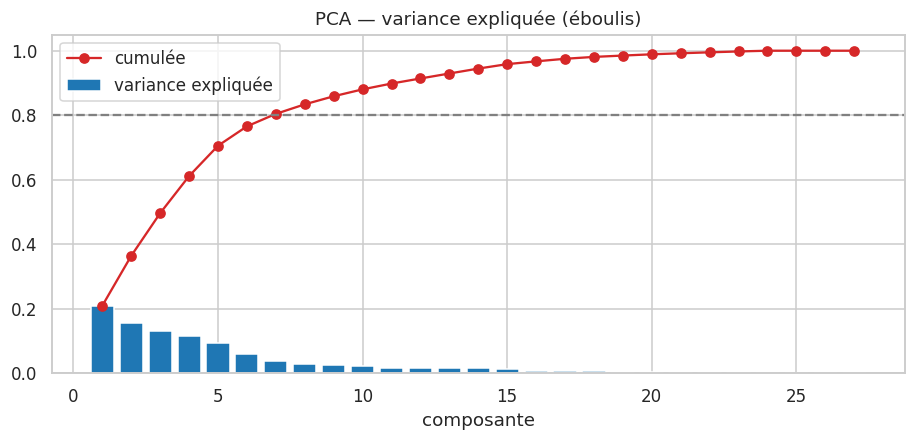

In [16]:
pca_full = PCA(random_state=SEED).fit(X_a)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n80, n90 = np.argmax(cum >= .80) + 1, np.argmax(cum >= .90) + 1
print(f"PC1 = {evr[0]:.1%}, PC2 = {evr[1]:.1%}, PC1+PC2 = {cum[1]:.1%}")
print(f"Composantes pour 80 % de variance : {n80} | pour 90 % : {n90}")
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, len(evr) + 1), evr, label="variance expliquée")
ax.plot(range(1, len(evr) + 1), cum, "o-", color="C3", label="cumulée")
ax.axhline(.8, ls="--", color="grey"); ax.set_xlabel("composante"); ax.legend()
ax.set_title("PCA — variance expliquée (éboulis)"); save(fig, "j1_pca_variance")

In [17]:
loadings = pd.DataFrame(pca_full.components_[:3].T, index=data["feature_names"], columns=["PC1", "PC2", "PC3"])
loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(10).round(3)

,PC1,PC2,PC3
euribor3m,0.633,-0.087,0.035
previous,-0.578,0.157,0.276
cons.conf.idx,0.322,0.050,0.713
campaign_log,0.198,-0.095,-0.290
poutcome_nonexistent,0.196,-0.050,-0.073
contact_cellular,-0.164,-0.014,-0.026
poutcome_failure,-0.143,0.035,0.031
age,0.099,0.656,0.300
education_level,-0.099,-0.643,0.441
default_flag,0.068,0.090,-0.033


La variance est **diffuse** : aucune composante ne domine (PC1+PC2 ≈ un tiers), ce qui est typique des données mixtes encodées en one-hot. PC1 est portée par le **contexte économique et l'historique de contact** (`euribor3m`, `previous`, `poutcome`, `contact_cellular`), PC2 par le **cycle de vie** (âge, métier retraité/étudiant, statut marital). Pour DBSCAN (Jour 3) on utilisera un espace PCA réduit couvrant ~80 % de la variance ou l'embedding UMAP.

In [18]:
Xs = X_a[sample_idx]
pca2 = PCA(n_components=2, random_state=SEED).fit_transform(Xs)
pca_k = PCA(n_components=n80, random_state=SEED).fit_transform(Xs)
tsne2 = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(Xs)
umap2 = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(Xs)

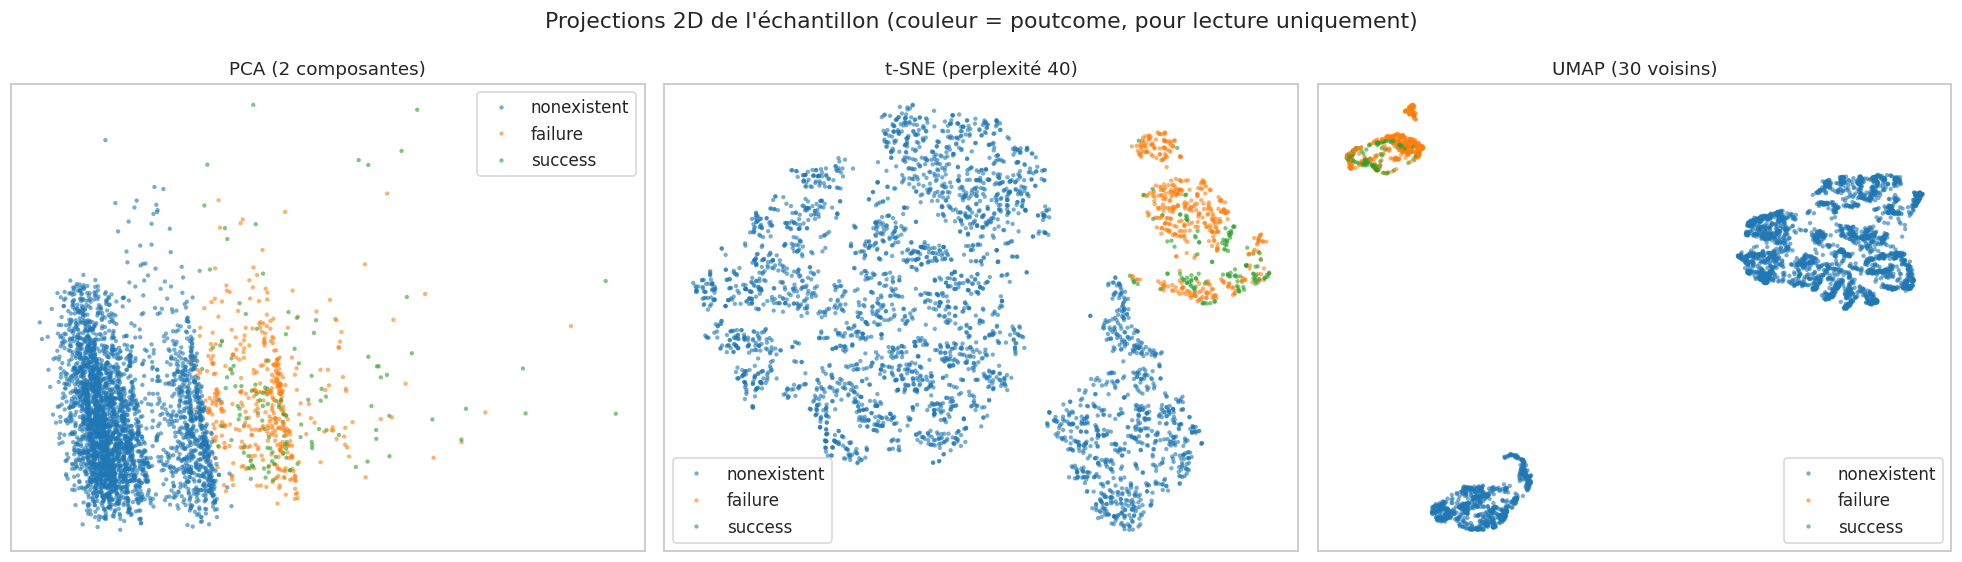

In [19]:
color_by = clean.iloc[sample_idx]["poutcome"].values
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, emb, t in zip(axes, [pca2, tsne2, umap2], ["PCA (2 composantes)", "t-SNE (perplexité 40)", "UMAP (30 voisins)"]):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=color_by, s=8, alpha=.6, ax=ax, linewidth=0)
    ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Projections 2D de l'échantillon (couleur = poutcome, pour lecture uniquement)")
fig.tight_layout(); save(fig, "j1_pca_tsne_umap")

**Lecture comparée** : la PCA (linéaire) montre un nuage peu séparé, alors que **t-SNE et UMAP** (non linéaires, préservant la structure locale) font apparaître des **îlots** nets — en particulier les clients déjà contactés (`poutcome` = failure/success) et des sous-groupes liés au contexte économique et au type de contact. UMAP préserve mieux la structure globale que t-SNE et sera réutilisé pour DBSCAN.

## 6. Sauvegarde des artefacts pour les jours suivants

In [20]:
clean.to_parquet(DATA_PROC / "clean.parquet")
mixed.to_parquet(DATA_PROC / "mixed.parquet")
y.to_frame().to_parquet(DATA_PROC / "y.parquet")
np.save(DATA_PROC / "X_a.npy", X_a)
np.save(DATA_PROC / "sample_idx.npy", sample_idx)
np.save(DATA_PROC / "emb_pca2.npy", pca2); np.save(DATA_PROC / "emb_pca_k.npy", pca_k)
np.save(DATA_PROC / "emb_tsne2.npy", tsne2); np.save(DATA_PROC / "emb_umap2.npy", umap2)
joblib.dump(data["pipeline"], MODELS / "preprocessing_pipeline.joblib")
pd.Series({"pca_n80": n80, "pca_n90": n90, "pc1": evr[0], "pc2": evr[1]}).to_csv(RESULTS / "j1_pca_summary.csv")
print("Artefacts sauvegardés.")

Artefacts sauvegardés.


**Livrable J1** : ce notebook + la fonction de prétraitement réutilisable `src/preprocessing.py::preprocess()` (et `transform_new_client()` pour affecter un nouveau client).